


# Objectif  : Récupérer, traiter et conditionné les données Aspect Portugal en format Raster(tif)
- gere l'unification des valeur aspect pour chaque Postion du raster
- fit les positon du raster avec notre grille 1km * 1km
- Conversion en csv


 Objectif  final : Construction Dataset Wild fire Portugal selon les variable du paper de l'inde


 Source aspect raster : https://portal.opentopography.org/map_overlay?url=https://ot-process3.sdsc.edu/appRasterVizService1770844894212123443694/&img=viz.be_slope.png&jobId=rt1770844862708


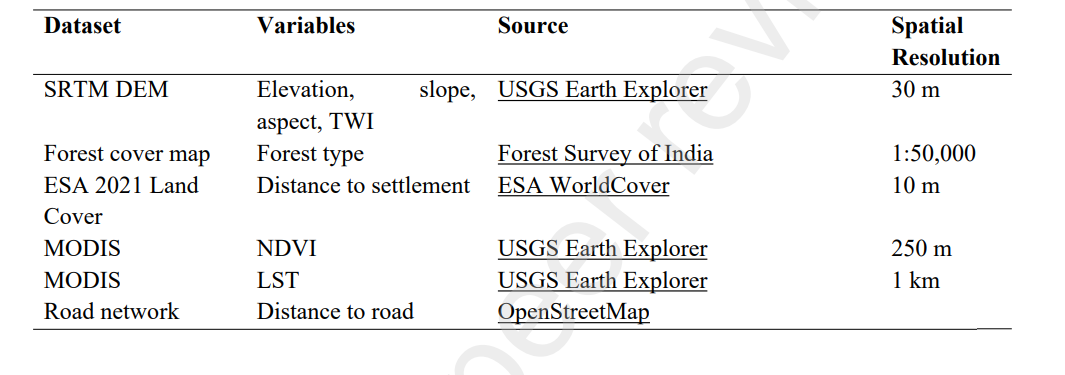

1. Imports & Configuration


In [1]:
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
from rasterio.mask import mask
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from shapely.geometry import Point
from tqdm import tqdm



2. Google Drive Rep

In [2]:
from google.colab import drive
drive.mount('/content/gdrive')


Mounted at /content/gdrive


3. Chemins des fichiers

In [3]:
csv_path    = "/content/gdrive/MyDrive/Projet big data dossier organisé /dataTraiter/grid_with_fire.csv"
raster_path ="/content/gdrive/MyDrive/Projet big data dossier organisé /dataBrute/viz.be_aspect.tif"
output_csv  = "/content/gdrive/MyDrive/Projet big data dossier organisé /dataTraiter/grid_with_fire_aspect.csv"
border_file = "/content/gdrive/MyDrive/Projet big data dossier organisé /dataBrute/pt/pt.shp"

4. Chargement des données


In [4]:
df = pd.read_csv(csv_path)


5. Création de la grille 1km x 1km


In [5]:
geometry = [Point(xy) for xy in zip(df.longitude, df.latitude)]
gdf = gpd.GeoDataFrame(df, geometry=geometry, crs="EPSG:4326")
gdf = gdf.to_crs(epsg=3763)
gdf['geometry'] = gdf.geometry.buffer(500, cap_style=3)

6. Calcul vectoriel de l'aspect moyen


In [6]:
aspect_means = []

with rasterio.open(raster_path) as src:
    if gdf.crs != src.crs:
        gdf = gdf.to_crs(src.crs)

    nodata = src.nodata if src.nodata is not None else -9999

    for geom in tqdm(gdf.geometry, desc="Extraction"):
        try:
            out_image, _ = mask(src, [geom], crop=True)
            data = out_image[0].astype('float32')

            valid_mask = (data != nodata) & (data >= 0)
            vals = data[valid_mask]

            if vals.size == 0:
                aspect_means.append(np.nan)
            else:
                rads = np.radians(vals)
                sin_mean = np.mean(np.sin(rads))
                cos_mean = np.mean(np.cos(rads))

                mean_deg = np.degrees(np.arctan2(sin_mean, cos_mean))
                if mean_deg < 0:
                    mean_deg += 360

                aspect_means.append(mean_deg)

        except Exception:
            aspect_means.append(np.nan)

Extraction: 100%|██████████| 89198/89198 [02:52<00:00, 517.80it/s]


7. Sauvegarde en CSV


In [7]:
df['mean_aspect'] = aspect_means
df.to_csv(output_csv, index=False)

print(f"Fichier sauvegardé : {output_csv}")
print(df[['latitude', 'longitude', 'mean_aspect']].head())

Fichier sauvegardé : /content/gdrive/MyDrive/Projet big data dossier organisé /dataTraiter/grid_with_fire_aspect.csv
    latitude  longitude  mean_aspect
0  36.987823  -7.963676   196.846283
1  36.994129  -8.952213   178.080078
2  36.996850  -7.974890   179.751862
3  37.003139  -8.952309   290.926086
4  37.003216  -8.941076   171.431244


8. Classification en 9 directions


In [8]:
def get_plot_class_9(val):
    if np.isnan(val):
        return 0

    val = val % 360

    if val >= 337.5 or val < 22.5:  return 1  # Nord
    elif 22.5  <= val < 67.5:        return 2  # Nord-Est
    elif 67.5  <= val < 112.5:       return 3  # Est
    elif 112.5 <= val < 157.5:       return 4  # Sud-Est
    elif 157.5 <= val < 202.5:       return 5  # Sud
    elif 202.5 <= val < 247.5:       return 6  # Sud-Ouest
    elif 247.5 <= val < 292.5:       return 7  # Ouest
    elif 292.5 <= val < 337.5:       return 8  # Nord-Ouest
    return 0

df['plot_class'] = df['mean_aspect'].apply(get_plot_class_9)

9. Visualisation cartographique


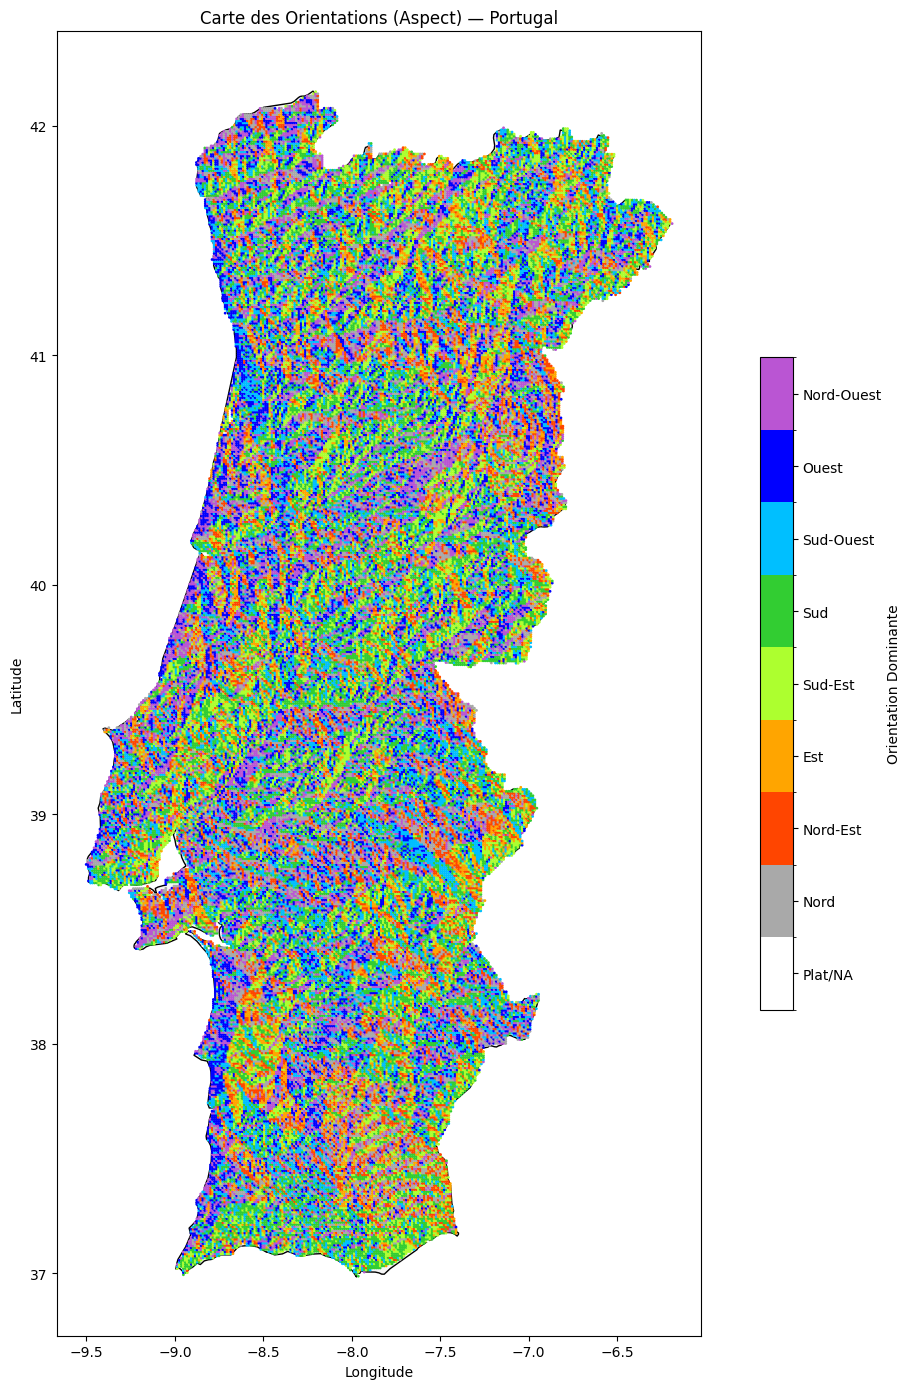

In [9]:
labels = ['Plat/NA', 'Nord', 'Nord-Est', 'Est', 'Sud-Est', 'Sud', 'Sud-Ouest', 'Ouest', 'Nord-Ouest']
colors = ['#FFFFFF','#A9A9A9', '#FF4500', '#FFA500', '#ADFF2F', '#32CD32', '#00BFFF', '#0000FF', '#BA55D3']


cmap = ListedColormap(colors)
norm = BoundaryNorm(np.arange(-0.5, 9.5, 1), cmap.N)

gdf_plot    = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.longitude, df.latitude), crs="EPSG:4326")
pt_boundary = gpd.read_file(border_file).to_crs(gdf_plot.crs)

fig, ax = plt.subplots(figsize=(12, 14))

pt_boundary.plot(ax=ax, color='#f5f5f5', edgecolor='black', linewidth=1, zorder=1)

scatter = ax.scatter(
    gdf_plot.geometry.x,
    gdf_plot.geometry.y,
    c=gdf_plot['plot_class'],
    cmap=cmap,
    norm=norm,
    s=1,
    zorder=2
)

cbar = plt.colorbar(scatter, ax=ax, ticks=np.arange(0, 9), shrink=0.5)
cbar.ax.set_yticklabels(labels)
cbar.set_label('Orientation Dominante')

plt.title("Carte des Orientations (Aspect) — Portugal")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.tight_layout()
plt.show()